# 04. Multilayer Perceptron (PyTorch)

Huấn luyện MLP theo **mini-batch**, thử một lưới cấu hình nhỏ, dừng sớm theo **Macro-F1 trên Validation**, rồi lưu checkpoint tốt nhất cùng bộ tiền xử lý đã fit.

Khác với Logistic và RF, MLP không dùng 5 fold: theo kế hoạch của nhóm, bộ tiền xử lý được fit trên **toàn bộ Train** rồi dùng để transform Validation, và Validation đóng vai trò tập dừng sớm.

**Đầu ra**

| Sản phẩm | Nơi lưu |
|---|---|
| Bảng thử cấu hình | `reports/tables/mlp/config_search.csv`, `config_runs.csv` |
| Lịch sử học (cấu hình chọn) | `reports/tables/mlp/history.csv`, `reports/figures/mlp/learning_curves.png` |
| Checkpoint tốt nhất | `artifacts/mlp_best.pt` (kèm `.json` mô tả) |
| Preprocessor đã fit | `artifacts/mlp_preprocessor.joblib` |
| Điểm Validation | `reports/tables/mlp/validation_summary.csv`, `validation_per_class.csv`, `validation_confusion.csv` |

## Mở dữ liệu

Chọn kernel Python đã cài các thư viện trong `requirements.txt`.

In [1]:
import copy
import hashlib
import json
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# Tìm thư mục gốc để notebook đọc đúng file, kể cả khi kernel chạy từ thư mục con.
current = Path.cwd().resolve()
root = next(
    (folder for folder in (current, *current.parents)
     if (folder / "common/preprocessing.py").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Mở thư mục student-dropout-prediction trong VS Code rồi chạy notebook.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from common.preprocessing import FEATURE_COLUMNS, LABELS, TARGET, make_preprocessor
from common.metrics import (
    DROPOUT_LABEL, SUMMARY_COLUMNS, confusion_frame, evaluate, per_class_frame, summary_frame,
)

data_path = root / "data/raw/data.csv"
split_path = root / "data/splits/splits.json"
# File UCI ngăn cột bằng dấu chấm phẩy. Xóa khoảng trắng thừa quanh tên cột.
data = pd.read_csv(data_path, sep=";", encoding="utf-8-sig")
data.columns = data.columns.str.strip()

# Thống nhất ký tự xuống dòng trước khi tính mã nhận diện CSV trên Windows và Linux.
csv_bytes = data_path.read_bytes().replace(b"\r\n", b"\n")
data_hash = hashlib.sha256(csv_bytes).hexdigest()

table_dir = root / "reports/tables/mlp"
figure_dir = root / "reports/figures/mlp"
artifact_dir = root / "artifacts"
for folder in (table_dir, figure_dir, artifact_dir):
    folder.mkdir(parents=True, exist_ok=True)

## 1. Lấy Train và Validation dùng chung

Đọc bộ chia của notebook 00. Chỉ số trong file là số dòng của CSV gốc, trùng với index của `data`, nên lấy dòng bằng `.loc`. Test không được đụng tới ở notebook này.

In [2]:
if not split_path.is_file():
    raise FileNotFoundError("Chạy 00_prepare_data.ipynb để tạo bộ chia.")
split = json.loads(split_path.read_text(encoding="utf-8"))
if split["sha256"] != data_hash or split["n_rows"] != len(data):
    raise ValueError("CSV hiện tại khác bản dùng để tạo bộ chia.")

SEED = split["seed"]
train_rows = split["train"]
validation_rows = split["validation"]
if set(train_rows) & set(validation_rows) or set(validation_rows) & set(split["test"]):
    raise ValueError("Train, Validation và Test bị chồng nhau.")

X = data[list(FEATURE_COLUMNS)]
y = data[TARGET]

print(f"Train {len(train_rows):,} sinh viên — Validation {len(validation_rows):,} sinh viên")
display(
    pd.DataFrame({
        "train": y.loc[train_rows].value_counts().reindex(LABELS),
        "validation": y.loc[validation_rows].value_counts().reindex(LABELS),
    }).rename_axis("Target")
)

Train 3,096 sinh viên — Validation 664 sinh viên


,train,validation
Target,,
Dropout,995,213
Enrolled,556,119
Graduate,1545,332


## 2. Tiền xử lý

Dùng `make_preprocessor(scale_numeric=True)`: cột số được chuẩn hóa (MLP học bằng gradient nên cần các cột cùng thang đo), cột phân loại được one-hot, cột nhị phân giữ 0/1.

Bộ xử lý **chỉ fit trên Train**, rồi dùng chính bộ đã fit để transform Validation. Nhãn được mã hóa thành số theo thứ tự chung `Dropout → Enrolled → Graduate` (0, 1, 2).

In [3]:
import joblib
import sklearn

preprocessor = make_preprocessor(scale_numeric=True).fit(X.loc[train_rows])
feature_names = preprocessor.get_feature_names_out()

X_train = preprocessor.transform(X.loc[train_rows]).astype(np.float32)
X_validation = preprocessor.transform(X.loc[validation_rows]).astype(np.float32)

LABEL_TO_CODE = {label: code for code, label in enumerate(LABELS)}
y_train = y.loc[train_rows].map(LABEL_TO_CODE).to_numpy(dtype=np.int64)
y_validation = y.loc[validation_rows].map(LABEL_TO_CODE).to_numpy(dtype=np.int64)

preprocessor_path = artifact_dir / "mlp_preprocessor.joblib"
joblib.dump(preprocessor, preprocessor_path)

print(f"scikit-learn {sklearn.__version__}")
print(f"{len(FEATURE_COLUMNS)} cột gốc → {X_train.shape[1]} đặc trưng sau tiền xử lý.")
print(f"Đã lưu {preprocessor_path.relative_to(root)}")

scikit-learn 1.9.1
36 cột gốc → 232 đặc trưng sau tiền xử lý.
Đã lưu artifacts\mlp_preprocessor.joblib


## 3. Mô hình và vòng huấn luyện

**Kiến trúc:** các khối `Linear → ReLU → Dropout`, cuối cùng là `Linear` ra 3 logit. Không có softmax trong mô hình vì `CrossEntropyLoss` đã tự tính.

**Huấn luyện theo batch:** mỗi epoch xáo Train bằng một bộ sinh số ngẫu nhiên có seed, chia thành các batch, cập nhật bằng `AdamW`.

**Dừng sớm:** sau mỗi epoch chấm Validation bằng `evaluate()` dùng chung. Giữ lại trọng số của epoch có Macro-F1 cao nhất; nếu `PATIENCE` epoch liên tiếp không cải thiện thì dừng.

**Trọng số lớp:** tùy chọn `balanced` nhân loss của mỗi lớp với `n_mẫu / (3 × n_mẫu_lớp)` — cùng công thức `class_weight="balanced"` của scikit-learn — để lớp Enrolled (18% Train) không bị bỏ qua.

In [4]:
import torch
from torch import nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MAX_EPOCHS = 300
PATIENCE = 30


class MLP(nn.Module):
    def __init__(self, n_features, hidden_sizes, dropout, n_classes=len(LABELS)):
        super().__init__()
        layers, width = [], n_features
        for size in hidden_sizes:
            layers += [nn.Linear(width, size), nn.ReLU(), nn.Dropout(dropout)]
            width = size
        layers.append(nn.Linear(width, n_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def balanced_weights(labels):
    counts = np.bincount(labels, minlength=len(LABELS))
    return torch.tensor(len(labels) / (len(LABELS) * counts), dtype=torch.float32)


def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# Đưa toàn bộ dữ liệu lên thiết bị một lần: dữ liệu nhỏ nên tự chia batch nhanh hơn DataLoader.
Xt_train = torch.tensor(X_train).to(DEVICE)
yt_train = torch.tensor(y_train).to(DEVICE)
Xt_validation = torch.tensor(X_validation).to(DEVICE)
yt_validation = torch.tensor(y_validation).to(DEVICE)


@torch.no_grad()
def predict_codes(model, features):
    model.eval()
    logits = model(features)
    return logits.argmax(dim=1).cpu().numpy(), logits


def train_mlp(config, seed):
    set_seed(seed)
    model = MLP(X_train.shape[1], config["hidden_sizes"], config["dropout"]).to(DEVICE)
    weights = balanced_weights(y_train).to(DEVICE) if config["class_weight"] == "balanced" else None
    loss_fn = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"],
    )
    # Bộ sinh riêng cho việc xáo batch để thứ tự batch chỉ phụ thuộc vào seed.
    generator = torch.Generator().manual_seed(seed)

    history, best = [], {"macro_f1": -1.0}
    epochs_without_gain = 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        order = torch.randperm(len(yt_train), generator=generator).to(DEVICE)
        running_loss = 0.0
        for start in range(0, len(order), config["batch_size"]):
            batch = order[start:start + config["batch_size"]]
            optimizer.zero_grad()
            loss = loss_fn(model(Xt_train[batch]), yt_train[batch])
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(batch)

        predicted, logits = predict_codes(model, Xt_validation)
        result = evaluate(y_validation, predicted)
        history.append({
            "epoch": epoch,
            "train_loss": running_loss / len(order),
            "validation_loss": loss_fn(logits, yt_validation).item(),
            "validation_macro_f1": result["macro_f1"],
            "validation_accuracy": result["accuracy"],
        })

        if result["macro_f1"] > best["macro_f1"]:
            best = {"macro_f1": result["macro_f1"], "epoch": epoch, "result": result,
                    "state_dict": copy.deepcopy(model.state_dict())}
            epochs_without_gain = 0
        else:
            epochs_without_gain += 1
            if epochs_without_gain >= PATIENCE:
                break

    model.load_state_dict(best["state_dict"])
    return model, best, pd.DataFrame(history)


print(f"torch {torch.__version__} trên {DEVICE}")

torch 2.15.0+cpu trên cpu


## 4. Thử cấu hình

Lưới nhỏ, tập trung vào ba câu hỏi: mạng rộng/sâu cỡ nào, dropout bao nhiêu, và có cần cân trọng số lớp như Logistic không. `lr=1e-3`, `weight_decay=1e-4`, `batch_size=64` giữ cố định.

| Thành phần | Giá trị |
|---|---|
| `hidden_sizes` | `(64,)`, `(128, 64)`, `(256, 128)` |
| `dropout` | 0.2, 0.4 |
| `class_weight` | `none`, `balanced` |

Mạng nơ-ron cho kết quả khác nhau theo seed khởi tạo, nên **mỗi cấu hình chạy 3 seed** và được xếp hạng theo Macro-F1 trung bình. Như vậy cấu hình được chọn vì ổn định, không phải vì một lần khởi tạo may mắn.

In [5]:
import itertools

SEEDS = (SEED, SEED + 1, SEED + 2)
FIXED = {"lr": 1e-3, "weight_decay": 1e-4, "batch_size": 64}

grid = [
    {"hidden_sizes": hidden, "dropout": dropout, "class_weight": class_weight, **FIXED}
    for hidden, dropout, class_weight in itertools.product(
        [(64,), (128, 64), (256, 128)], [0.2, 0.4], ["none", "balanced"],
    )
]

runs = []
started = time.perf_counter()
for config_id, config in enumerate(grid):
    for seed in SEEDS:
        _, best, history = train_mlp(config, seed)
        runs.append({
            "config_id": config_id, "seed": seed,
            "best_epoch": best["epoch"], "epochs_run": len(history),
            **{metric: best["result"][metric] for metric in SUMMARY_COLUMNS},
        })
print(f"{len(grid)} cấu hình × {len(SEEDS)} seed = {len(runs)} lần train "
      f"trong {time.perf_counter() - started:.0f}s.")

config_frame = pd.DataFrame([
    {"config_id": config_id, "hidden_sizes": str(config["hidden_sizes"]),
     "dropout": config["dropout"], "class_weight": config["class_weight"]}
    for config_id, config in enumerate(grid)
]).set_index("config_id")

run_scores = config_frame.join(pd.DataFrame(runs).set_index("config_id")).reset_index()
run_scores.to_csv(table_dir / "config_runs.csv", index=False)

12 cấu hình × 3 seed = 36 lần train trong 491s.


In [6]:
search = (
    run_scores.groupby("config_id")
    .agg(
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        accuracy_mean=("accuracy", "mean"),
        dropout_recall_mean=("dropout_recall", "mean"),
        dropout_f2_mean=("dropout_f2", "mean"),
        best_epoch_mean=("best_epoch", "mean"),
    )
)
search = config_frame.join(search)

# Cùng quy tắc xếp hạng với nhánh Logistic: Macro-F1 làm tròn 4 chữ số,
# bằng điểm thì ưu tiên std nhỏ (ổn định giữa các seed), rồi F2 Dropout.
order = (
    pd.DataFrame({
        "rounded": search["macro_f1_mean"].round(4),
        "std": search["macro_f1_std"],
        "f2": search["dropout_f2_mean"],
    })
    .sort_values(["rounded", "std", "f2"], ascending=[False, True, False])
    .index
)
search = search.loc[order]
search.to_csv(table_dir / "config_search.csv")
display(search.round(4))

,hidden_sizes,dropout,class_weight,macro_f1_mean,macro_f1_std,accuracy_mean,dropout_recall_mean,dropout_f2_mean,best_epoch_mean
config_id,,,,,,,,,
7,"(128, 64)",0.4,balanced,0.7054,0.0063,0.7465,0.7433,0.7597,13.0000
0,"(64,)",0.2,none,0.7019,0.0031,0.7766,0.7606,0.7724,12.3333
8,"(256, 128)",0.2,none,0.7014,0.0094,0.7686,0.7418,0.7550,6.6667
2,"(64,)",0.4,none,0.7007,0.0047,0.7721,0.7606,0.7714,21.0000
6,"(128, 64)",0.4,none,0.7000,0.0020,0.7706,0.7934,0.7931,13.3333
5,"(128, 64)",0.2,balanced,0.6999,0.0023,0.7344,0.7089,0.7313,6.6667
10,"(256, 128)",0.4,none,0.6989,0.0079,0.7701,0.7606,0.7690,8.0000
4,"(128, 64)",0.2,none,0.6977,0.0044,0.7696,0.7700,0.7768,6.6667
1,"(64,)",0.2,balanced,0.6975,0.0014,0.7405,0.7261,0.7440,15.3333


### Nhận xét

**Các cấu hình gần như ngang nhau.** Macro-F1 trung bình của 12 cấu hình chỉ trải từ 0.6953 đến 0.7054 (chênh 0.010), còn từng lần chạy dao động 0.686–0.711. Cấu hình đứng đầu chỉ hơn cấu hình thứ hai 0.0035 — nhỏ hơn cả std theo seed của chính nó (0.0063). Vì vậy thứ hạng trong bảng phần lớn là nhiễu; cấu hình được chọn vì quy tắc xếp hạng đã định trước, không phải vì vượt trội rõ rệt.

**Kích thước mạng không tạo khác biệt.** Trung bình theo kiến trúc: `(64,)` 0.6988, `(128, 64)` 0.7007, `(256, 128)` 0.6982. Mạng lớn hơn chỉ đạt đỉnh sớm hơn (epoch tốt nhất khoảng 6–9 với `(256, 128)`) rồi bắt đầu khớp nhiễu. Với khoảng 3,100 mẫu Train, thêm tầng hay thêm nơ-ron không đem lại thông tin mới.

**`class_weight` không quyết định như ở Logistic.** Trung bình Macro-F1: `balanced` 0.6984, `none` 0.7001 — gần như bằng nhau — nhưng `balanced` làm accuracy giảm từ 0.7713 xuống 0.7409. Một cách giải thích: dừng sớm theo Macro-F1 đã tự chọn epoch mà Enrolled được dự đoán đủ nhiều, nên phần việc mà trọng số lớp làm ở Logistic một phần đã được dừng sớm làm thay. Cấu hình thắng dùng `balanced`, nhưng chỉ hơn không đáng kể.

**Nếu ưu tiên cảnh báo Dropout:** cấu hình `(128, 64)`, dropout 0.4, `none` có F2 Dropout cao nhất bảng (0.7931 so với 0.7597) trong khi Macro-F1 chỉ kém 0.005. Đây là phương án thay thế hợp lý nếu nhóm chọn tiêu chí theo recall Dropout.

## 5. Cấu hình được chọn và lịch sử học

Lấy dòng đầu của bảng. Checkpoint bàn giao là lần chạy với **seed chung của nhóm (42)** của cấu hình này — không chọn seed có điểm cao nhất, để tránh cộng thêm may mắn vào con số báo cáo.

In [7]:
best_id = int(search.index[0])
best_config = grid[best_id]

model, best, history = train_mlp(best_config, SEED)
history.to_csv(table_dir / "history.csv", index=False)

print("Cấu hình được chọn")
for field, value in best_config.items():
    print(f"  {field:14s} {value}")
print(f"\nMacro-F1 Validation qua {len(SEEDS)} seed: "
      f"{search.loc[best_id, 'macro_f1_mean']:.4f} ± {search.loc[best_id, 'macro_f1_std']:.4f}")
print(f"Seed {SEED}: epoch tốt nhất {best['epoch']} / {len(history)} epoch đã chạy, "
      f"Macro-F1 {best['macro_f1']:.4f}")

Cấu hình được chọn
  hidden_sizes   (128, 64)
  dropout        0.4
  class_weight   balanced
  lr             0.001
  weight_decay   0.0001
  batch_size     64

Macro-F1 Validation qua 3 seed: 0.7054 ± 0.0063
Seed 42: epoch tốt nhất 14 / 44 epoch đã chạy, Macro-F1 0.7075


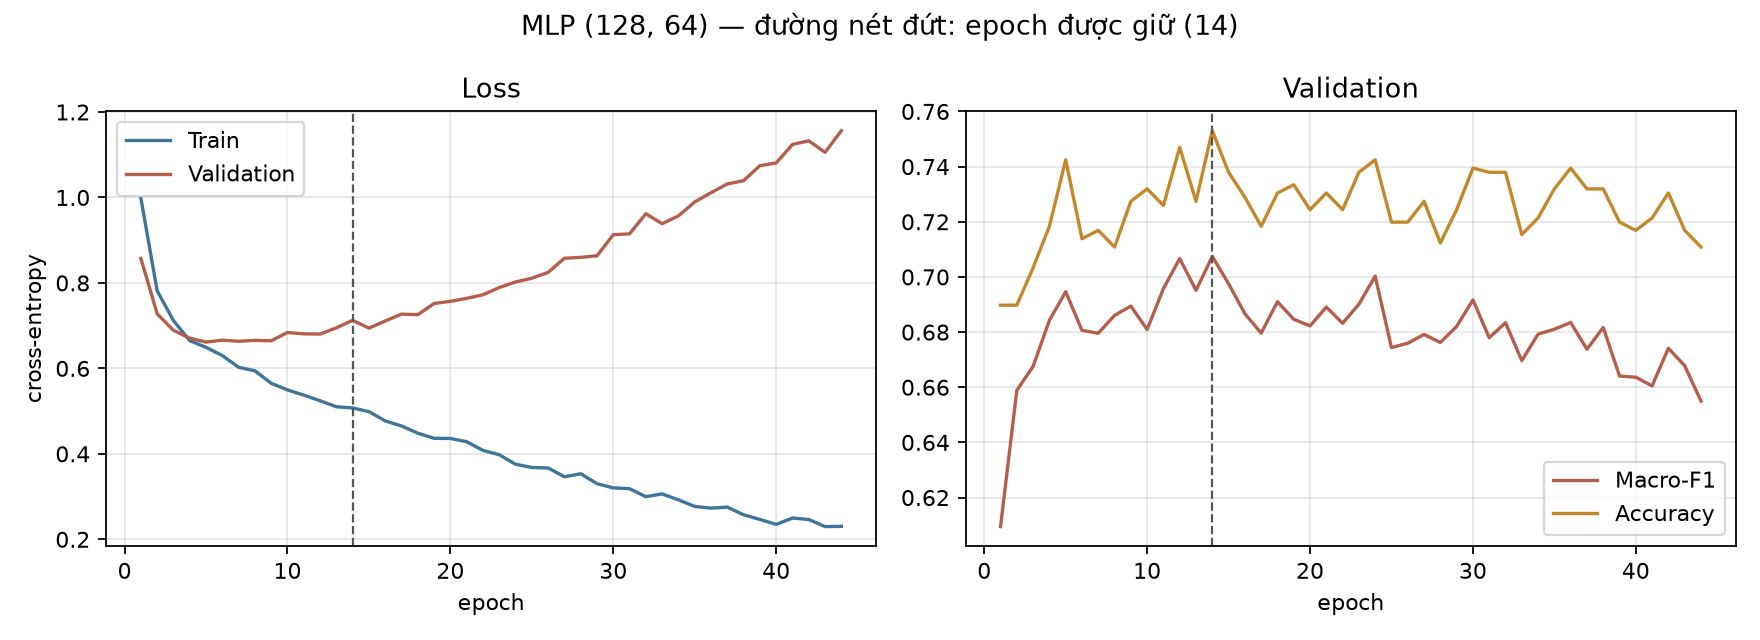

In [8]:
import matplotlib.pyplot as plt
from IPython.display import Image


def show_and_save(figure, filename):
    path = figure_dir / filename
    figure.tight_layout()
    figure.savefig(path, dpi=160)
    plt.close(figure)
    display(Image(filename=str(path)))


figure, (loss_ax, score_ax) = plt.subplots(1, 2, figsize=(11, 4))
loss_ax.plot(history["epoch"], history["train_loss"], color="#3F7599", label="Train")
loss_ax.plot(history["epoch"], history["validation_loss"], color="#B45F4D", label="Validation")
loss_ax.set(xlabel="epoch", ylabel="cross-entropy", title="Loss")
loss_ax.legend()

score_ax.plot(history["epoch"], history["validation_macro_f1"], color="#B45F4D", label="Macro-F1")
score_ax.plot(history["epoch"], history["validation_accuracy"], color="#C3872C", label="Accuracy")
score_ax.set(xlabel="epoch", title="Validation")
score_ax.legend()

for ax in (loss_ax, score_ax):
    ax.axvline(best["epoch"], color="#555555", linestyle="--", linewidth=1)
    ax.grid(alpha=0.3)
figure.suptitle(f"MLP {best_config['hidden_sizes']} — đường nét đứt: epoch được giữ ({best['epoch']})")
show_and_save(figure, "learning_curves.png")

### Nhận xét

**Mô hình overfit nhanh.** Loss trên Train giảm đều từ 1.00 xuống 0.23, còn loss trên Validation thấp nhất quanh epoch 5–6 (khoảng 0.66) rồi tăng liên tục lên 1.16 ở epoch 44. Mạng `(128, 64)` có khoảng 38 nghìn tham số trong khi Train chỉ có 3,096 mẫu, nên sau khoảng 10 epoch nó bắt đầu học thuộc Train dù đã có dropout 0.4 và weight decay.

**Macro-F1 đạt đỉnh muộn hơn loss (epoch 14 so với 5–6).** Hai đại lượng đo hai thứ khác nhau: loss phạt nặng những dự đoán sai mà mô hình rất tự tin, còn Macro-F1 chỉ xét lớp có xác suất cao nhất. Loss tăng trong khi Macro-F1 chưa giảm nghĩa là **xác suất đầu ra ngày càng quá tự tin**. Nếu sau này nhóm dùng xác suất (ví dụ đặt ngưỡng cảnh báo Dropout) thay vì chỉ lấy nhãn, cần hiệu chỉnh xác suất trước.

**Đường Macro-F1 răng cưa**, dao động 0.01–0.02 giữa hai epoch liền nhau. Việc giữ đúng epoch cao nhất trên Validation vì vậy cũng cộng thêm một phần may mắn vào điểm báo cáo (xem phần Bàn giao). Huấn luyện dừng ở epoch 44 = epoch 14 + 30 epoch chờ (`PATIENCE`).

## 6. Lưu checkpoint tốt nhất

Checkpoint chứa trọng số **và** cấu hình kiến trúc, nên nhánh khác dựng lại được mô hình mà không cần đoán kích thước lớp. Đọc lại ngay sau khi lưu và so dự đoán để chắc file bàn giao dùng được.

In [9]:
checkpoint_path = artifact_dir / "mlp_best.pt"
torch.save({
    "state_dict": {name: tensor.cpu() for name, tensor in best["state_dict"].items()},
    "n_features": int(X_train.shape[1]),
    "hidden_sizes": list(best_config["hidden_sizes"]),
    "dropout": best_config["dropout"],
    "labels": list(LABELS),
    "best_epoch": best["epoch"],
}, checkpoint_path)

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
reloaded = MLP(checkpoint["n_features"], checkpoint["hidden_sizes"], checkpoint["dropout"])
reloaded.load_state_dict(checkpoint["state_dict"])
reloaded_preprocessor = joblib.load(preprocessor_path)
features = torch.from_numpy(
    reloaded_preprocessor.transform(X.loc[validation_rows]).astype(np.float32)
)
if not np.array_equal(predict_codes(reloaded, features)[0],
                      predict_codes(model, Xt_validation)[0]):
    raise ValueError("Checkpoint đọc lại cho dự đoán khác mô hình vừa train.")
print(f"Đã lưu {checkpoint_path.relative_to(root)} "
      f"({checkpoint_path.stat().st_size / 1024:.0f} KB) và kiểm tra đọc lại.")

Đã lưu artifacts\mlp_best.pt (153 KB) và kiểm tra đọc lại.


## 7. Điểm trên Validation

Chấm checkpoint đã lưu trên 664 sinh viên Validation bằng `evaluate()` dùng chung. Dummy `most_frequent` fit trên cùng Train làm mốc tham chiếu tối thiểu.

In [10]:
from sklearn.dummy import DummyClassifier

predicted = predict_codes(model, Xt_validation)[0]
validation_result = evaluate(y_validation, predicted)

reference = DummyClassifier(strategy="most_frequent").fit(X.loc[train_rows], y.loc[train_rows])
reference_result = evaluate(y.loc[validation_rows], reference.predict(X.loc[validation_rows]))

validation_summary = summary_frame({
    "MLP": validation_result,
    "Dummy (most_frequent)": reference_result,
})
validation_summary.to_csv(table_dir / "validation_summary.csv")
validation_per_class = per_class_frame(validation_result)
validation_per_class.to_csv(table_dir / "validation_per_class.csv")
confusion = confusion_frame(validation_result)
confusion.to_csv(table_dir / "validation_confusion.csv")

print(f"Validation: {validation_result['n_samples']:,} sinh viên")
display(validation_summary.round(4))
display(validation_per_class.round(4))
display(confusion)

Validation: 664 sinh viên


,accuracy,macro_f1,dropout_recall,dropout_precision,dropout_f2
model,,,,,
MLP,0.753,0.7075,0.7465,0.8238,0.7608
Dummy (most_frequent),0.500,0.2222,0.0000,0.0000,0.0000


,precision,recall,f1,f2,support
Dropout,0.8238,0.7465,0.7833,0.7608,213
Enrolled,0.4558,0.5630,0.5038,0.5377,119
Graduate,0.8457,0.8253,0.8354,0.8293,332


dự đoán,Dropout,Enrolled,Graduate
thực tế,,,
Dropout,159,38,16
Enrolled,18,67,34
Graduate,16,42,274


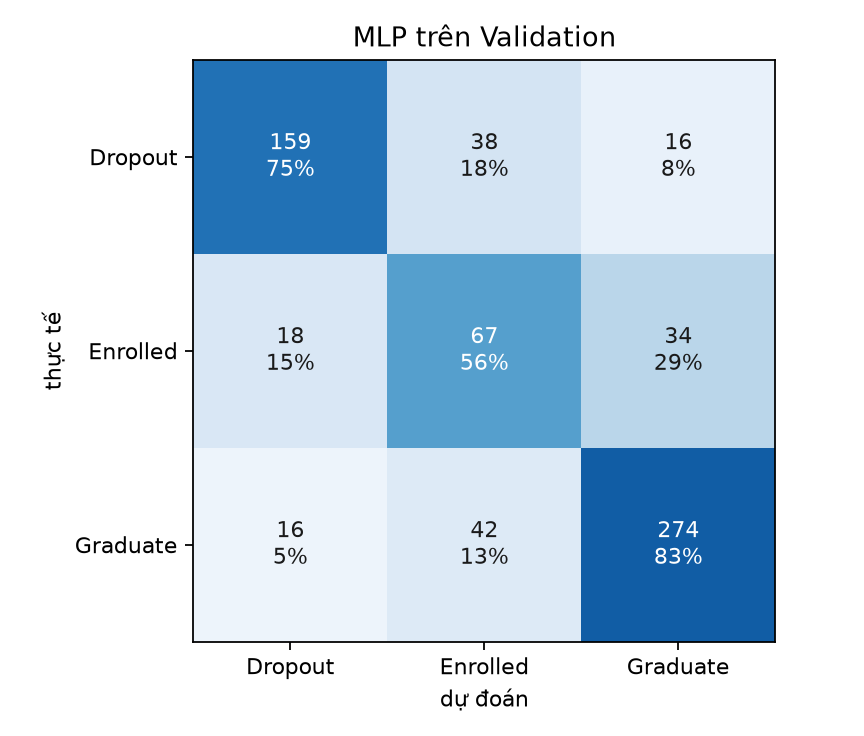

In [11]:
figure, ax = plt.subplots(figsize=(5.4, 4.6))
# Chia mỗi dòng cho support của dòng đó: màu thể hiện tỉ lệ trong từng lớp thực tế.
shares = confusion.to_numpy() / confusion.to_numpy().sum(axis=1, keepdims=True)
ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
for row in range(len(LABELS)):
    for column in range(len(LABELS)):
        count = confusion.to_numpy()[row, column]
        ax.text(column, row, f"{count}\n{shares[row, column]:.0%}",
                ha="center", va="center",
                color="white" if shares[row, column] > 0.5 else "#1A1A1A")
ax.set(xticks=range(len(LABELS)), yticks=range(len(LABELS)),
       xlabel="dự đoán", ylabel="thực tế", title="MLP trên Validation")
ax.set_xticklabels(LABELS)
ax.set_yticklabels(LABELS)
show_and_save(figure, "validation_confusion.png")

### Nhận xét

**Điểm bàn giao: Macro-F1 = 0.7075 trên Validation** (accuracy 0.7530, Dropout recall 0.7465, Dropout precision 0.8238, Dropout F2 0.7608). Dummy chỉ đạt Macro-F1 0.2222 và không nhận ra sinh viên Dropout nào.

**Enrolled vẫn là điểm yếu.** F1 từng lớp: Graduate 0.8354, Dropout 0.7833, Enrolled 0.5038. Trong 147 sinh viên được gán Enrolled chỉ 67 là đúng — 38 Dropout và 42 Graduate bị kéo vào — nên precision của Enrolled chỉ 0.4558. Ngược lại, 34/119 sinh viên Enrolled bị gán Graduate. Enrolled là trạng thái trung gian nên đặc trưng của nó chen giữa hai lớp còn lại; MLP không tách được tốt hơn mô hình tuyến tính bao nhiêu.

**Nhìn theo mục tiêu cảnh báo sớm:** mô hình nhận ra 159/213 sinh viên bỏ học. Trong 54 trường hợp bỏ sót, 38 bị gán Enrolled (vẫn là tín hiệu "chưa tốt nghiệp") và 16 bị gán Graduate — đây là kiểu lỗi đáng lo nhất vì sinh viên có nguy cơ lại bị xem là an toàn.

**Chưa đủ căn cứ để nói MLP tốt hơn mô hình tuyến tính.** Con số 0.7075 đã được chọn trên chính Validation (chọn epoch và chọn cấu hình), nên nó lạc quan hơn điểm Validation của các nhánh chọn cấu hình bằng 5 fold. Mức dao động giữa các seed của riêng cấu hình này đã là ±0.006. Việc so sánh công bằng giữa bốn phương pháp nên làm ở bước tổng hợp trên Test.

In [12]:
metadata = {
    "model": "MLP (PyTorch)",
    "created_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "notebook": "notebooks/models/mlp/04_mlp.ipynb",
    "torch_version": torch.__version__,
    "sklearn_version": sklearn.__version__,
    "data_sha256": data_hash,
    "split_seed": SEED,
    "labels": list(LABELS),
    "n_features_in": len(FEATURE_COLUMNS),
    "n_features_after_preprocess": int(X_train.shape[1]),
    "scale_numeric": True,
    "preprocessor": "artifacts/mlp_preprocessor.joblib",
    "best_config": {
        **{key: (list(value) if isinstance(value, tuple) else value)
           for key, value in best_config.items()},
        "optimizer": "AdamW",
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "early_stopping_metric": "validation_macro_f1",
        "seed": SEED,
    },
    "best_epoch": best["epoch"],
    "config_search": {
        "n_configs": len(grid),
        "seeds": list(SEEDS),
        "selection_metric": "validation_macro_f1_mean",
        "macro_f1_mean": float(search.loc[best_id, "macro_f1_mean"]),
        "macro_f1_std": float(search.loc[best_id, "macro_f1_std"]),
    },
    "validation": {metric: float(validation_result[metric]) for metric in SUMMARY_COLUMNS},
}
metadata_path = checkpoint_path.with_suffix(".json")
with metadata_path.open("w", encoding="utf-8", newline="\n") as output:
    json.dump(metadata, output, indent=2, ensure_ascii=False)
    output.write("\n")

print(f"Đã lưu {metadata_path.relative_to(root)}")
print(json.dumps(metadata["validation"], indent=2))

Đã lưu artifacts\mlp_best.json
{
  "accuracy": 0.7530120481927711,
  "macro_f1": 0.707458827893957,
  "dropout_recall": 0.7464788732394366,
  "dropout_precision": 0.8238341968911918,
  "dropout_f2": 0.7607655502392344
}


## Bàn giao

**Cấu hình đã chốt:** MLP `232 → 128 → 64 → 3`, ReLU, dropout 0.4; `CrossEntropyLoss` với `class_weight="balanced"`; `AdamW(lr=1e-3, weight_decay=1e-4)`; `batch_size=64`; dừng sớm theo Macro-F1 Validation với `PATIENCE=30`, tối đa 300 epoch; seed 42 → epoch tốt nhất là 14. Bộ tiền xử lý là `make_preprocessor(scale_numeric=True)` fit trên toàn bộ Train.

**Điểm để đưa vào bảng so sánh:** Macro-F1 **0.7075** trên 664 sinh viên Validation (trung bình 3 seed: 0.7054 ± 0.0063). Kèm ghi chú rằng Validation đã được dùng để dừng sớm và chọn cấu hình.

**Thời gian chạy:** khoảng 12 phút trên CPU laptop cho toàn bộ notebook (36 lần train ở mục 4). Chỉ cần dùng lại mô hình thì không phải chạy lại — đọc checkpoint như hướng dẫn bên dưới.

| Sản phẩm | Đường dẫn |
|---|---|
| Notebook | `notebooks/models/mlp/04_mlp.ipynb` |
| Bảng thử cấu hình | `reports/tables/mlp/config_search.csv`, `config_runs.csv` |
| Lịch sử học | `reports/tables/mlp/history.csv`, `reports/figures/mlp/learning_curves.png` |
| Checkpoint tốt nhất | `artifacts/mlp_best.pt` |
| Mô tả checkpoint | `artifacts/mlp_best.json` |
| Preprocessor đã fit | `artifacts/mlp_preprocessor.joblib` |
| Điểm Validation | `reports/tables/mlp/validation_summary.csv`, `validation_per_class.csv`, `validation_confusion.csv` |
| Biểu đồ | `reports/figures/mlp/learning_curves.png`, `validation_confusion.png` |

**Dùng lại mô hình ở nhánh khác** — chép class `MLP` ở mục 3 rồi:

```python
import joblib, torch
from common.preprocessing import FEATURE_COLUMNS, LABELS

preprocessor = joblib.load("artifacts/mlp_preprocessor.joblib")
checkpoint = torch.load("artifacts/mlp_best.pt", map_location="cpu", weights_only=True)
model = MLP(checkpoint["n_features"], checkpoint["hidden_sizes"], checkpoint["dropout"])
model.load_state_dict(checkpoint["state_dict"])
model.eval()

features = torch.tensor(preprocessor.transform(df[list(FEATURE_COLUMNS)]), dtype=torch.float32)
with torch.no_grad():
    probabilities = torch.softmax(model(features), dim=1).numpy()  # cột theo thứ tự LABELS
codes = probabilities.argmax(axis=1)                                # evaluate() nhận thẳng mã 0/1/2
```

**Chỗ còn vướng — cần nhóm thống nhất trước khi tổng hợp**

1. **Điểm Validation của MLP lạc quan hơn của Logistic/RF.** Validation vừa dùng để dừng sớm, vừa dùng để chọn cấu hình, nên con số ở mục 7 đã "nhìn" Validation; Logistic/RF chọn bằng 5 fold trong Train nên Validation của họ là tập giữ riêng thật sự. Khi so sánh, nên ghi rõ điều này, hoặc so trên **Test** ở bước tổng hợp cuối. Nếu nhóm muốn so công bằng hơn, có thể đổi sang: tách một phần Train làm tập dừng sớm và để Validation chỉ chấm một lần.
2. **Kết quả MLP dao động theo seed** (xem std ở mục 4). Nên báo cáo kèm khoảng dao động chứ không chỉ một con số.
3. **Tập Test chưa được dùng.** Theo quy ước, Test chỉ mở một lần ở bước tổng hợp cuối.